In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from xgboost import XGBClassifier
from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    roc_auc_score,
    average_precision_score,
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
  )
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer

churn = pd.read_csv("Telco-Customer-Churn.csv", header =0)
#print(churn.head(5))
#print(churn.shape)
#print(churn.info())
#print(churn.describe())
#print(churn.columns)

churn['Churn'].value_counts()
churn['Churn'].value_counts(normalize=True)
churn['TotalCharges'] = pd.to_numeric(churn['TotalCharges'], errors='coerce')
#churn.info()
#print(
#churn['customerID'].duplicated().sum(),
#churn.isnull().sum().sort_values(ascending=False))
(churn == ' ').sum()
churn.dtypes
churn['TotalCharges'] = pd.to_numeric(
    churn['TotalCharges'],
    errors='coerce'
)
X = churn.drop(columns = ['Churn','customerID'], axis=1)
Y = churn['Churn']
#print(Y, X)
Y = Y.replace({'No': 0, 'Yes': 1})
#print(Y)
pd.crosstab(
    churn['Contract'],
    churn['Churn'],
    normalize='index'
)
churn['TenureGroup'] = pd.cut(
    churn['tenure'],
    bins=[0, 12, 24, 36, 48, 60, 72],
    labels=['0-12', '13-24', '25-36',
            '37-48', '49-60', '61-72']

)

pd.crosstab(
    churn['TenureGroup'],
    churn['Churn'],
    normalize='index'
)

from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    Y,
    test_size=0.20,
    random_state=42,
    stratify=Y
)

numerical_features = ['tenure', 'MonthlyCharges', 'TotalCharges']
categorical_features = ['gender', 'SeniorCitizen', 'Partner', 'Dependents', 'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod']
numerical_pipeline = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='mean')),
    ('scaler', StandardScaler())
])
categorical_pipeline = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('encoder', OneHotEncoder(handle_unknown='ignore'))
])

preprocessor = ColumnTransformer(
    transformers=[
        ('num', numerical_pipeline, numerical_features),
        ('cat', categorical_pipeline, categorical_features)
    ]
)
log_model = Pipeline(steps=[
    ('preprocessor',preprocessor),
    ('classifier', LogisticRegression(max_iter = 500, random_state = 42))
])

log_model.fit(X_train, y_train)
log_p = log_model.predict(X_test)
y_prob = log_model.predict_proba(X_test)[:, 1]
#print(y_prob)

print("Accuracy:", accuracy_score(y_test, log_p))
print("Precision:", precision_score(y_test, log_p))
print("Recall:", recall_score(y_test, log_p))
print("F1:", f1_score(y_test, log_p))
print("ROC-AUC:", roc_auc_score(y_test, y_prob))
print("PR-AUC:", average_precision_score(y_test, y_prob))

print("\nClassification Report:")
print(classification_report(y_test, log_p))

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, log_p))
results = X_test.copy()

results['ActualChurn'] = y_test.values
results['PredictedChurn'] = log_p
results['ChurnProbability'] = y_prob

results.head()
results.sort_values(
    'ChurnProbability',
    ascending=False
).head(20)

#predict_proba()

/tmp/ipykernel_950/3935728757.py:45: FutureWarning: Downcasting behavior in `replace` is deprecated and will be removed in a future version. To retain the old behavior, explicitly call `result.infer_objects(copy=False)`. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  Y = Y.replace({'No': 0, 'Yes': 1})


Accuracy: 0.8055358410220014
Precision: 0.6572327044025157
Recall: 0.5588235294117647
F1: 0.6040462427745664
ROC-AUC: 0.8417138133250666
PR-AUC: 0.6340368973258657

Classification Report:
              precision    recall  f1-score   support

           0       0.85      0.89      0.87      1035
           1       0.66      0.56      0.60       374

    accuracy                           0.81      1409
   macro avg       0.75      0.73      0.74      1409
weighted avg       0.80      0.81      0.80      1409


Confusion Matrix:
[[926 109]
 [165 209]]


,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,...,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,ActualChurn,PredictedChurn,ChurnProbability
3380,Male,1,Yes,No,1,Yes,Yes,Fiber optic,No,No,...,Yes,Yes,Month-to-month,Yes,Electronic check,95.10,95.10,1,1,0.855404
6866,Male,0,No,No,1,Yes,Yes,Fiber optic,No,No,...,Yes,Yes,Month-to-month,Yes,Electronic check,95.45,95.45,1,1,0.832655
2631,Male,1,Yes,No,7,Yes,Yes,Fiber optic,No,No,...,Yes,Yes,Month-to-month,Yes,Electronic check,99.25,665.45,1,1,0.829180
6365,Male,1,Yes,No,7,Yes,Yes,Fiber optic,No,No,...,Yes,Yes,Month-to-month,Yes,Electronic check,101.95,700.85,1,1,0.822628
4585,Female,1,No,No,1,Yes,Yes,Fiber optic,No,No,...,No,Yes,Month-to-month,Yes,Electronic check,85.05,85.05,1,1,0.818956
2797,Male,0,No,No,3,Yes,Yes,Fiber optic,No,No,...,Yes,Yes,Month-to-month,Yes,Electronic check,100.95,329.95,1,1,0.818426
3727,Female,0,No,No,3,Yes,Yes,Fiber optic,No,No,...,Yes,Yes,Month-to-month,Yes,Electronic check,96.60,291.90,1,1,0.818054
3346,Female,1,No,No,2,Yes,Yes,Fiber optic,No,No,...,No,Yes,Month-to-month,Yes,Electronic check,84.05,186.05,0,1,0.817772
6894,Male,1,Yes,No,3,Yes,Yes,Fiber optic,No,Yes,...,Yes,Yes,Month-to-month,Yes,Electronic check,105.90,334.65,1,1,0.817212
4039,Male,0,No,No,7,Yes,Yes,Fiber optic,No,No,...,Yes,Yes,Month-to-month,Yes,Electronic check,94.10,701.30,0,1,0.812297


In [2]:
rand_model = Pipeline(steps=[
    ('preprocessor', preprocessor),
    ('classifier', RandomForestClassifier(n_estimators=300 ,random_state=42, class_weight='balanced'))
])
rand_model.fit(X_train,y_train)
rand_p = rand_model.predict(X_test)
y_rand_prob = rand_model.predict_proba(X_test)[:, 1]
print("Accuracy:", accuracy_score(y_test, rand_p))
print("Precision:", precision_score(y_test, rand_p))
print("Recall:", recall_score(y_test, rand_p))
print("F1:", f1_score(y_test, rand_p))
print("ROC-AUC:", roc_auc_score(y_test, y_rand_prob))
print("PR-AUC:", average_precision_score(y_test, y_rand_prob))

print("\nClassification Report:")
print(classification_report(y_test, rand_p))

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, rand_p))
results_random = X_test.copy()

results_random['ActualChurn'] = y_test.values
results_random['PredictedChurn'] = rand_p
results_random['ChurnProbability'] = y_rand_prob

results_random.head()
results_random.sort_values(
    'ChurnProbability',
    ascending=False
).head(20)



Accuracy: 0.7849538679914834
Precision: 0.624561403508772
Recall: 0.47593582887700536
F1: 0.5402124430955993
ROC-AUC: 0.8206153607688134
PR-AUC: 0.6129408061658799

Classification Report:
              precision    recall  f1-score   support

           0       0.83      0.90      0.86      1035
           1       0.62      0.48      0.54       374

    accuracy                           0.78      1409
   macro avg       0.73      0.69      0.70      1409
weighted avg       0.77      0.78      0.77      1409


Confusion Matrix:
[[928 107]
 [196 178]]


,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,...,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,ActualChurn,PredictedChurn,ChurnProbability
1739,Male,0,No,No,1,Yes,No,Fiber optic,No,No,...,No,No,Month-to-month,Yes,Electronic check,69.90,69.90,1,1,1.000000
2927,Male,0,No,No,1,Yes,No,Fiber optic,No,No,...,No,No,Month-to-month,Yes,Electronic check,69.90,69.90,0,1,1.000000
6623,Male,1,No,No,1,Yes,Yes,Fiber optic,No,No,...,No,No,Month-to-month,Yes,Electronic check,76.45,76.45,1,1,0.996667
1731,Female,1,No,No,1,Yes,No,Fiber optic,No,No,...,No,No,Month-to-month,Yes,Electronic check,69.60,69.60,1,1,0.996667
2194,Male,0,No,No,1,Yes,No,Fiber optic,No,No,...,Yes,No,Month-to-month,Yes,Electronic check,79.50,79.50,1,1,0.990000
809,Male,0,No,No,1,Yes,No,Fiber optic,No,No,...,No,No,Month-to-month,Yes,Electronic check,69.55,69.55,1,1,0.986667
4585,Female,1,No,No,1,Yes,Yes,Fiber optic,No,No,...,No,Yes,Month-to-month,Yes,Electronic check,85.05,85.05,1,1,0.976667
1144,Male,0,No,No,1,No,No phone service,DSL,No,No,...,No,Yes,Month-to-month,Yes,Electronic check,35.55,35.55,1,1,0.970000
3727,Female,0,No,No,3,Yes,Yes,Fiber optic,No,No,...,Yes,Yes,Month-to-month,Yes,Electronic check,96.60,291.90,1,1,0.970000
3346,Female,1,No,No,2,Yes,Yes,Fiber optic,No,No,...,No,Yes,Month-to-month,Yes,Electronic check,84.05,186.05,0,1,0.970000


In [3]:
bost_model = Pipeline(steps=[
    ('preprocessor',preprocessor),
    ('classifier', XGBClassifier(     n_estimators=300,
        learning_rate=0.05,
        max_depth=4,
        subsample=0.8,
        colsample_bytree=0.8,
        random_state=42,
        eval_metric='logloss'))
])

bost_model.fit(X_train,y_train)
bost_p = bost_model.predict(X_test)
bost_prob = bost_model.predict_proba(X_test)[:, 1]

print("Accuracy:", accuracy_score(y_test, bost_p))
print("Precision:", precision_score(y_test, bost_p))
print("Recall:", recall_score(y_test, bost_p))
print("F1:", f1_score(y_test, bost_p))
print("ROC-AUC:", roc_auc_score(y_test, bost_prob))
print("PR-AUC:", average_precision_score(y_test, bost_prob))

print("\nClassification Report:")
print(classification_report(y_test, bost_p))

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, bost_p))
results_bost = X_test.copy()

results_bost['ActualChurn'] = y_test.values
results_bost['PredictedChurn'] = bost_p
results_bost['ChurnProbability'] =bost_prob

results_bost.head()
results_bost.sort_values(
    'ChurnProbability',
    ascending=False
).head(20)


Accuracy: 0.8005677785663591
Precision: 0.6565656565656566
Recall: 0.5213903743315508
F1: 0.5812220566318927
ROC-AUC: 0.8440995634090264
PR-AUC: 0.6598735007960775

Classification Report:
              precision    recall  f1-score   support

           0       0.84      0.90      0.87      1035
           1       0.66      0.52      0.58       374

    accuracy                           0.80      1409
   macro avg       0.75      0.71      0.73      1409
weighted avg       0.79      0.80      0.79      1409


Confusion Matrix:
[[933 102]
 [179 195]]


,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,...,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,ActualChurn,PredictedChurn,ChurnProbability
2631,Male,1,Yes,No,7,Yes,Yes,Fiber optic,No,No,...,Yes,Yes,Month-to-month,Yes,Electronic check,99.25,665.45,1,1,0.955394
6623,Male,1,No,No,1,Yes,Yes,Fiber optic,No,No,...,No,No,Month-to-month,Yes,Electronic check,76.45,76.45,1,1,0.946219
2464,Female,0,No,No,1,Yes,Yes,Fiber optic,No,No,...,No,No,Month-to-month,Yes,Electronic check,77.15,77.15,1,1,0.942676
4585,Female,1,No,No,1,Yes,Yes,Fiber optic,No,No,...,No,Yes,Month-to-month,Yes,Electronic check,85.05,85.05,1,1,0.940455
6866,Male,0,No,No,1,Yes,Yes,Fiber optic,No,No,...,Yes,Yes,Month-to-month,Yes,Electronic check,95.45,95.45,1,1,0.937834
3380,Male,1,Yes,No,1,Yes,Yes,Fiber optic,No,No,...,Yes,Yes,Month-to-month,Yes,Electronic check,95.10,95.10,1,1,0.933540
1731,Female,1,No,No,1,Yes,No,Fiber optic,No,No,...,No,No,Month-to-month,Yes,Electronic check,69.60,69.60,1,1,0.926096
1073,Male,0,No,No,7,Yes,Yes,Fiber optic,No,No,...,Yes,Yes,Month-to-month,Yes,Bank transfer (automatic),98.05,713.00,1,1,0.925552
2194,Male,0,No,No,1,Yes,No,Fiber optic,No,No,...,Yes,No,Month-to-month,Yes,Electronic check,79.50,79.50,1,1,0.923776
2900,Female,1,Yes,Yes,1,Yes,No,Fiber optic,No,No,...,No,No,Month-to-month,Yes,Electronic check,69.25,69.25,1,1,0.922158


In [4]:
import numpy as np
from sklearn.metrics import precision_score, recall_score, f1_score

threshold_results = []

for threshold in np.arange(0.20, 0.71, 0.05):

    predictions = (
        log_p >= threshold
    ).astype(int)

    threshold_results.append({
        'Threshold': threshold,
        'Precision': precision_score(y_test, predictions),
        'Recall': recall_score(y_test, predictions),
        'F1': f1_score(y_test, predictions)
    })

threshold_df = pd.DataFrame(threshold_results)

print(threshold_df)

    Threshold  Precision    Recall        F1
0        0.20   0.657233  0.558824  0.604046
1        0.25   0.657233  0.558824  0.604046
2        0.30   0.657233  0.558824  0.604046
3        0.35   0.657233  0.558824  0.604046
4        0.40   0.657233  0.558824  0.604046
5        0.45   0.657233  0.558824  0.604046
6        0.50   0.657233  0.558824  0.604046
7        0.55   0.657233  0.558824  0.604046
8        0.60   0.657233  0.558824  0.604046
9        0.65   0.657233  0.558824  0.604046
10       0.70   0.657233  0.558824  0.604046


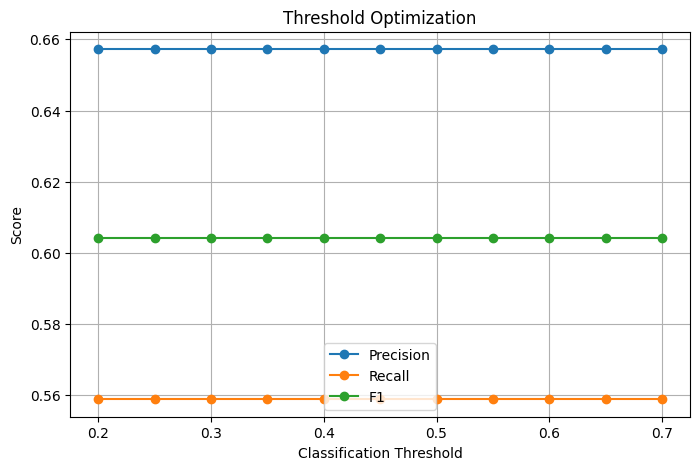

In [5]:
plt.figure(figsize=(8, 5))

plt.plot(
    threshold_df['Threshold'],
    threshold_df['Precision'],
    marker='o',
    label='Precision'
)

plt.plot(
    threshold_df['Threshold'],
    threshold_df['Recall'],
    marker='o',
    label='Recall'
)

plt.plot(
    threshold_df['Threshold'],
    threshold_df['F1'],
    marker='o',
    label='F1'
)

plt.xlabel("Classification Threshold")
plt.ylabel("Score")
plt.title("Threshold Optimization")
plt.legend()
plt.grid()
plt.show()

In [6]:
xgb_model = Pipeline(steps=[
    ('preprocessor', preprocessor),
    ('classifier', XGBClassifier(
        n_estimators=500,
        learning_rate=0.01,
        max_depth=4,
        min_child_weight=3,
        subsample=0.8,
        colsample_bytree=0.8,
        reg_alpha=0.1,
        reg_lambda=1.0,
        eval_metric='logloss',
        random_state=42
    ))
])

In [7]:
xgb_model.fit(X_train, y_train)
xgb_p = xgb_model.predict(X_test)
xgb_prob = xgb_model.predict_proba(X_test)[:, 1]

#model_compare["XGBoost_tunned"] = [metrics_value(xgb_p)[3], metrics_value(xgb_p)[0], metrics_value(xgb_p)[1], metrics_value(xgb_p)[4], metrics_value(xgb_p)[5], metrics_value(xgb_p)[2]]
#model_compare

In [8]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    average_precision_score
)

def metrics_value(y_true, predictions, probabilities):
    return {
        'Accuracy': accuracy_score(y_true, predictions),
        'Precision': precision_score(y_true, predictions, zero_division=0),
        'Recall': recall_score(y_true, predictions, zero_division=0),
        'F1': f1_score(y_true, predictions, zero_division=0),
        'ROC-AUC': roc_auc_score(y_true, probabilities),
        'PR-AUC': average_precision_score(y_true, probabilities)
    }

log_metrics = metrics_value(y_test, log_p, y_prob)
rf_metrics = metrics_value(y_test, rand_p, y_rand_prob)
xgb_metrics = metrics_value(y_test, bost_p, bost_prob)
tuned_xgb_metrics = metrics_value(y_test, xgb_p, xgb_prob)

model_compare = pd.DataFrame({
    'Logistic Regression': log_metrics,
    'Random Forest': rf_metrics,
    'XGBoost': xgb_metrics,
    'Tuned XGBoost': tuned_xgb_metrics
}).T

model_compare

,Accuracy,Precision,Recall,F1,ROC-AUC,PR-AUC
Logistic Regression,0.805536,0.657233,0.558824,0.604046,0.841714,0.634037
Random Forest,0.784954,0.624561,0.475936,0.540212,0.820615,0.612941
XGBoost,0.800568,0.656566,0.521390,0.581222,0.844100,0.659874
Tuned XGBoost,0.809794,0.677852,0.540107,0.601190,0.847829,0.662237


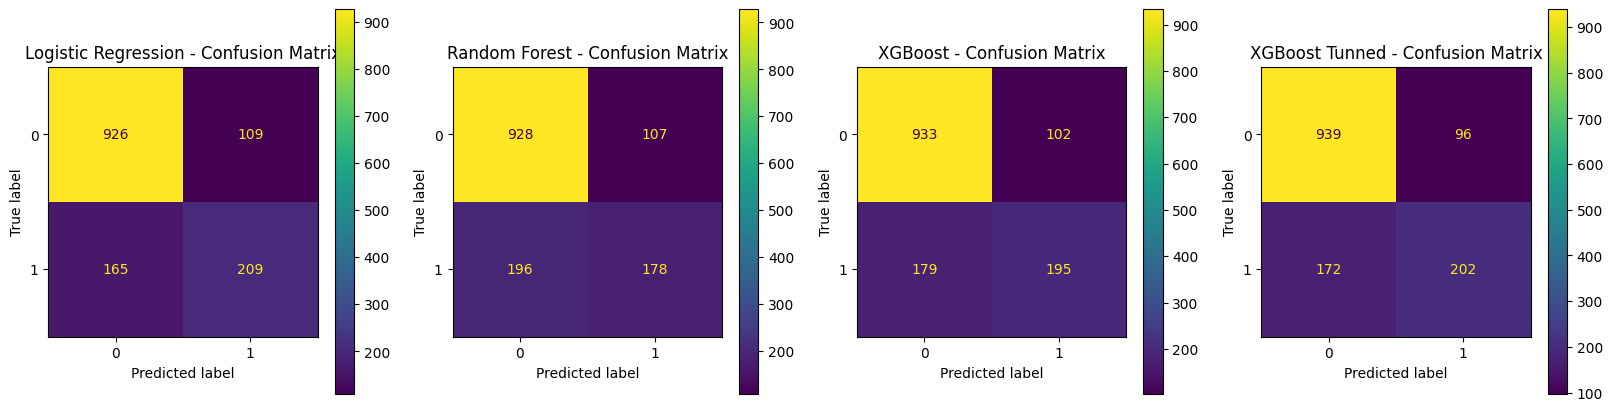

In [9]:
from sklearn.metrics import ConfusionMatrixDisplay
import matplotlib.pyplot as plt
#plt.figure(figsize=(40,20))
fig, axes = plt.subplots(nrows=1,ncols= 4,figsize=(20,5))

ConfusionMatrixDisplay.from_predictions(
    y_test,
    log_p,
    ax=axes[0]

).ax_.set_title("Logistic Regression - Confusion Matrix")

ConfusionMatrixDisplay.from_predictions(
    y_test,
    rand_p,
    ax=axes[1]
).ax_.set_title("Random Forest - Confusion Matrix")


ConfusionMatrixDisplay.from_predictions(
    y_test,
    bost_p,
    ax=axes[2]
).ax_.set_title("XGBoost - Confusion Matrix")

ConfusionMatrixDisplay.from_predictions(
    y_test,
    xgb_p,
    ax=axes[3]
).ax_.set_title("XGBoost Tunned - Confusion Matrix")

plt.show()

In [10]:
from sklearn.model_selection import cross_validate, StratifiedKFold

cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

cv_results = cross_validate(
    xgb_model,
    X_train,
    y_train,
    cv=cv,
    scoring=['accuracy', 'precision', 'recall', 'f1', 'roc_auc'],
    n_jobs=-1
)

print("Mean Accuracy:",
      cv_results['test_accuracy'].mean())

print("Mean Precision:",
      cv_results['test_precision'].mean())

print("Mean Recall:",
      cv_results['test_recall'].mean())

print("Mean F1:",
      cv_results['test_f1'].mean())

print("Mean ROC-AUC:",
      cv_results['test_roc_auc'].mean())

Mean Accuracy: 0.8065342686615151
Mean Precision: 0.6720935056917203
Mean Recall: 0.5297658862876254
Mean F1: 0.5922344812307317
Mean ROC-AUC: 0.8500451460765918


In [11]:
param_grid = {
    'classifier__max_depth': [2, 3, 4, 5, 6]
}
from sklearn.model_selection import GridSearchCV

grid = GridSearchCV(
    xgb_model,
    param_grid=param_grid,
    scoring='f1',
    cv=cv,
    n_jobs=-1
)

grid.fit(X_train, y_train)

print(grid.best_params_)
print(grid.best_score_)

{'classifier__max_depth': 4}
0.5922344812307317


In [12]:
param_grid = {
    'classifier__learning_rate': [0.01, 0.03, 0.05, 0.1],
    'classifier__n_estimators': [200, 300, 500, 700]
}

grid = GridSearchCV(
    xgb_model,
    param_grid=param_grid,
    scoring='f1',
    cv=cv,
    n_jobs=-1
)

grid.fit(X_train, y_train)

print("Best parameters:", grid.best_params_)
print("Best CV F1:", grid.best_score_)

Best parameters: {'classifier__learning_rate': 0.01, 'classifier__n_estimators': 500}
Best CV F1: 0.5922344812307317


In [13]:
from sklearn.model_selection import RandomizedSearchCV

param_distributions = {
    'classifier__n_estimators': [200, 300, 500, 700, 1000],
    'classifier__learning_rate': [0.01, 0.03, 0.05, 0.1, 0.15],
    'classifier__max_depth': [2, 3, 4, 5, 6],
    'classifier__min_child_weight': [1, 3, 5, 7],
    'classifier__subsample': [0.6, 0.7, 0.8, 0.9, 1.0],
    'classifier__colsample_bytree': [0.6, 0.7, 0.8, 0.9, 1.0],
    'classifier__gamma': [0, 0.1, 0.3, 0.5, 1],
    'classifier__reg_alpha': [0, 0.01, 0.1, 0.5, 1],
    'classifier__reg_lambda': [0.5, 1, 2, 5, 10]
}
random_search = RandomizedSearchCV(
    estimator=xgb_model,
    param_distributions=param_distributions,
    n_iter=30,
    scoring='f1',
    cv=cv,
    random_state=42,
    n_jobs=-1,
    verbose=1
)

random_search.fit(X_train, y_train)

best_xgb = random_search.best_estimator_

print("Best parameters:")
print(random_search.best_params_)

print("Best CV F1:")
print(random_search.best_score_)

Fitting 5 folds for each of 30 candidates, totalling 150 fits
Best parameters:
{'classifier__subsample': 0.8, 'classifier__reg_lambda': 0.5, 'classifier__reg_alpha': 0, 'classifier__n_estimators': 500, 'classifier__min_child_weight': 1, 'classifier__max_depth': 2, 'classifier__learning_rate': 0.03, 'classifier__gamma': 0, 'classifier__colsample_bytree': 1.0}
Best CV F1:
0.593346157171105


In [14]:
# Final XGBoost model using the best parameters found by RandomizedSearchCV.
# Keeping this explicit makes the final model reproducible and easy to explain.

best_params = random_search.best_params_

xgboost_model = Pipeline(steps=[
    ('preprocessor', preprocessor),
    ('classifier', XGBClassifier(
        n_estimators=best_params['classifier__n_estimators'],
        learning_rate=best_params['classifier__learning_rate'],
        max_depth=best_params['classifier__max_depth'],
        min_child_weight=best_params['classifier__min_child_weight'],
        subsample=best_params['classifier__subsample'],
        colsample_bytree=best_params['classifier__colsample_bytree'],
        gamma=best_params['classifier__gamma'],
        reg_alpha=best_params['classifier__reg_alpha'],
        reg_lambda=best_params['classifier__reg_lambda'],
        eval_metric='logloss',
        random_state=42,
        n_jobs=-1
    ))
])

xgboost_model.fit(X_train, y_train)

xgboost_p = xgboost_model.predict(X_test)
xgboost_prob = xgboost_model.predict_proba(X_test)[:, 1]

final_xgb_metrics = metrics_value(
    y_test,
    xgboost_p,
    xgboost_prob
)

print("Final tuned XGBoost metrics:")
print(final_xgb_metrics)

Final tuned XGBoost metrics:
{'Accuracy': 0.8090844570617459, 'Precision': 0.6804123711340206, 'Recall': 0.5294117647058824, 'F1': 0.5954887218045113, 'ROC-AUC': np.float64(0.8467720685111988), 'PR-AUC': np.float64(0.6671285451809186)}


In [15]:
def threshold_analysis(y_true, probabilities):

    results = []

    for threshold in np.arange(0.10, 0.71, 0.05):

        predictions = (
            probabilities >= threshold
        ).astype(int)

        results.append({
            'Threshold': round(threshold, 2),
            'Precision': precision_score(
                y_true, predictions
            ),
            'Recall': recall_score(
                y_true, predictions
            ),
            'F1': f1_score(
                y_true, predictions
            )
        })

    return pd.DataFrame(results)

In [16]:
# Threshold analysis for the FINAL tuned XGBoost model

xgb_threshold_df = threshold_analysis(
    y_test,
    xgboost_prob
)

display(xgb_threshold_df)

best_threshold_row = xgb_threshold_df.loc[
    xgb_threshold_df['F1'].idxmax()
]

print("Best threshold by F1:")
print(best_threshold_row)

,Threshold,Precision,Recall,F1
0,0.10,0.411215,0.941176,0.572358
1,0.15,0.447263,0.895722,0.596616
2,0.20,0.476048,0.850267,0.610365
3,0.25,0.504983,0.812834,0.622951
4,0.30,0.525641,0.767380,0.623913
5,0.35,0.562762,0.719251,0.631455
6,0.40,0.596698,0.676471,0.634085
7,0.45,0.627451,0.598930,0.612859
8,0.50,0.680412,0.529412,0.595489
9,0.55,0.702041,0.459893,0.555735


Best threshold by F1:
Threshold    0.400000
Precision    0.596698
Recall       0.676471
F1           0.634085
Name: 6, dtype: float64


In [17]:
log_threshold_df = threshold_analysis(
    y_test,
    y_prob
)

xgb_threshold_df = threshold_analysis(
    y_test,
    xgboost_prob
)

print("LOGISTIC REGRESSION")
display(log_threshold_df)

print("XGBOOST")
display(xgb_threshold_df)

LOGISTIC REGRESSION


,Threshold,Precision,Recall,F1
0,0.10,0.405963,0.946524,0.568218
1,0.15,0.438462,0.914439,0.592721
2,0.20,0.467836,0.855615,0.604915
3,0.25,0.500000,0.810160,0.618367
4,0.30,0.518382,0.754011,0.614379
5,0.35,0.544330,0.705882,0.614668
6,0.40,0.569476,0.668449,0.615006
7,0.45,0.600522,0.614973,0.607662
8,0.50,0.657233,0.558824,0.604046
9,0.55,0.678431,0.462567,0.550079


XGBOOST


,Threshold,Precision,Recall,F1
0,0.10,0.411215,0.941176,0.572358
1,0.15,0.447263,0.895722,0.596616
2,0.20,0.476048,0.850267,0.610365
3,0.25,0.504983,0.812834,0.622951
4,0.30,0.525641,0.767380,0.623913
5,0.35,0.562762,0.719251,0.631455
6,0.40,0.596698,0.676471,0.634085
7,0.45,0.627451,0.598930,0.612859
8,0.50,0.680412,0.529412,0.595489
9,0.55,0.702041,0.459893,0.555735


# Final Model Selection

At this stage we have trained Logistic Regression, Random Forest, and XGBoost and tuned XGBoost using stratified cross-validation. The next step is to select the final model using the corrected metrics and business objective rather than model complexity alone.

In [18]:
# Final model comparison

final_comparison = pd.DataFrame({
    'Logistic Regression': metrics_value(y_test, log_p, y_prob),
    'Random Forest': metrics_value(y_test, rand_p, y_rand_prob),
    'XGBoost': metrics_value(y_test, bost_p, bost_prob),
    'Tuned XGBoost': metrics_value(y_test, xgboost_p, xgboost_prob)
}).T

display(final_comparison.sort_values('F1', ascending=False))

,Accuracy,Precision,Recall,F1,ROC-AUC,PR-AUC
Logistic Regression,0.805536,0.657233,0.558824,0.604046,0.841714,0.634037
Tuned XGBoost,0.809084,0.680412,0.529412,0.595489,0.846772,0.667129
XGBoost,0.800568,0.656566,0.521390,0.581222,0.844100,0.659874
Random Forest,0.784954,0.624561,0.475936,0.540212,0.820615,0.612941


## Threshold Optimization

The default classification threshold is 0.50. For churn, recall can be more valuable because missing a customer who is likely to churn may mean losing the opportunity to intervene. We therefore inspect the precision/recall/F1 trade-off before selecting the operating threshold.

In [19]:
# Find the threshold that maximizes F1

best_threshold = float(
    xgb_threshold_df.loc[
        xgb_threshold_df['F1'].idxmax(),
        'Threshold'
    ]
)

print(f"Selected threshold based on maximum F1: {best_threshold:.2f}")

final_predictions = (
    xgboost_prob >= best_threshold
).astype(int)

print("\nFinal model at selected threshold")
print("Accuracy :", accuracy_score(y_test, final_predictions))
print("Precision:", precision_score(y_test, final_predictions, zero_division=0))
print("Recall   :", recall_score(y_test, final_predictions, zero_division=0))
print("F1       :", f1_score(y_test, final_predictions, zero_division=0))
print("ROC-AUC  :", roc_auc_score(y_test, xgboost_prob))
print("PR-AUC   :", average_precision_score(y_test, xgboost_prob))

print("\nClassification Report:")
print(classification_report(y_test, final_predictions, zero_division=0))

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, final_predictions))

Selected threshold based on maximum F1: 0.40

Final model at selected threshold
Accuracy : 0.7927608232789212
Precision: 0.5966981132075472
Recall   : 0.6764705882352942
F1       : 0.6340852130325815
ROC-AUC  : 0.8467720685111988
PR-AUC   : 0.6671285451809186

Classification Report:
              precision    recall  f1-score   support

           0       0.88      0.83      0.86      1035
           1       0.60      0.68      0.63       374

    accuracy                           0.79      1409
   macro avg       0.74      0.76      0.74      1409
weighted avg       0.80      0.79      0.80      1409


Confusion Matrix:
[[864 171]
 [121 253]]


# Feature Importance and SHAP Explainability

For a retention use case, a prediction alone is not enough. We want to understand which customer attributes are driving churn risk. SHAP provides local and global explanations for the final XGBoost model.

,Feature,MeanAbsSHAP
0,num__tenure,0.556881
37,cat__Contract_Month-to-month,0.534566
17,cat__InternetService_Fiber optic,0.282392
1,num__MonthlyCharges,0.243103
19,cat__OnlineSecurity_No,0.219728
28,cat__TechSupport_No,0.170751
39,cat__Contract_Two year,0.165768
44,cat__PaymentMethod_Electronic check,0.162988
40,cat__PaperlessBilling_No,0.148522
13,cat__MultipleLines_No,0.129337


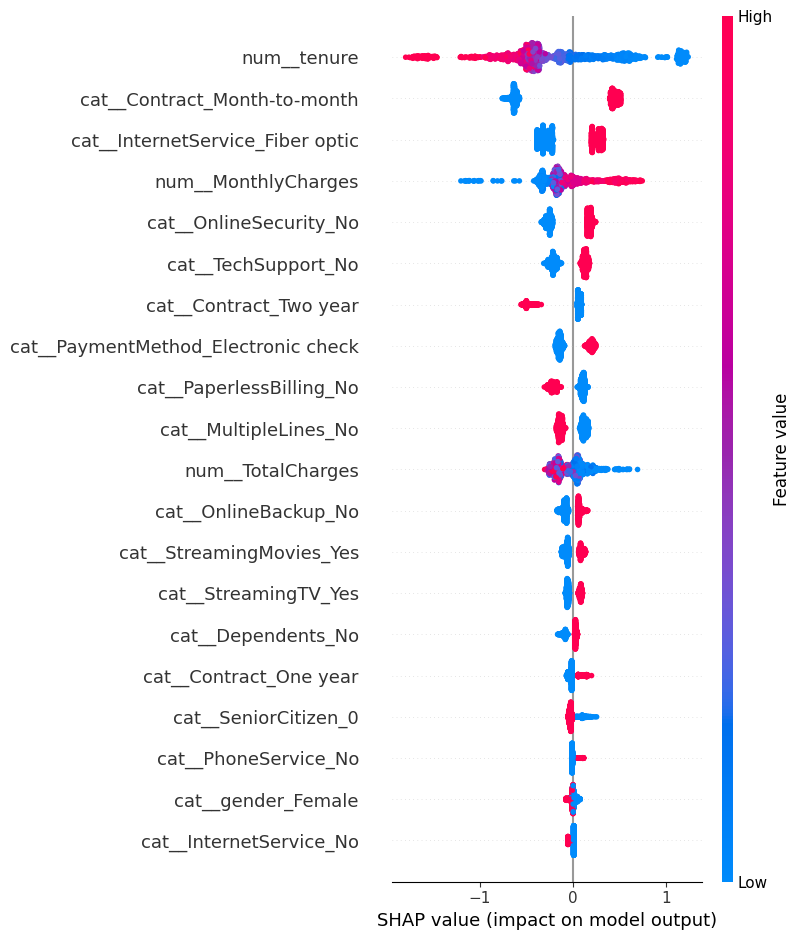

In [20]:
# Install SHAP in Colab if required:
# !pip install -q shap

import shap

# Transform the test data using the fitted preprocessing pipeline
fitted_preprocessor = xgboost_model.named_steps['preprocessor']
fitted_classifier = xgboost_model.named_steps['classifier']

X_test_transformed = fitted_preprocessor.transform(X_test)
feature_names = fitted_preprocessor.get_feature_names_out()

# SHAP explanation for the tree model
explainer = shap.TreeExplainer(fitted_classifier)
shap_values = explainer.shap_values(X_test_transformed)

# Global feature importance
shap_importance = pd.DataFrame({
    'Feature': feature_names,
    'MeanAbsSHAP': np.abs(shap_values).mean(axis=0)
}).sort_values('MeanAbsSHAP', ascending=False)

display(shap_importance.head(20))

shap.summary_plot(
    shap_values,
    X_test_transformed,
    feature_names=feature_names,
    max_display=20
)

# Customer Risk Scoring

Create an actionable customer-level table containing the customer ID, churn probability, predicted churn, risk segment, and retention recommendation.

In [21]:
# Build customer-level churn scoring table

customer_scores = X_test.copy()

customer_scores['customerID'] = churn.loc[X_test.index, 'customerID']
customer_scores['ActualChurn'] = y_test
customer_scores['ChurnProbability'] = xgboost_prob
customer_scores['PredictedChurn'] = final_predictions

# Risk bands are intentionally separate from the classification threshold.
customer_scores['RiskSegment'] = pd.cut(
    customer_scores['ChurnProbability'],
    bins=[-np.inf, 0.30, 0.60, np.inf],
    labels=['Low Risk', 'Medium Risk', 'High Risk']
)

def retention_action(row):
    if row['RiskSegment'] == 'High Risk':
        return 'Priority retention outreach'
    elif row['RiskSegment'] == 'Medium Risk':
        return 'Targeted retention offer'
    else:
        return 'Monitor and maintain engagement'

customer_scores['RetentionAction'] = customer_scores.apply(
    retention_action,
    axis=1
)

customer_scores = customer_scores.sort_values(
    'ChurnProbability',
    ascending=False
)

display(
    customer_scores[
        [
            'customerID',
            'ChurnProbability',
            'PredictedChurn',
            'RiskSegment',
            'RetentionAction'
        ]
    ].head(20)
)

,customerID,ChurnProbability,PredictedChurn,RiskSegment,RetentionAction
3380,5178-LMXOP,0.928475,1,High Risk,Priority retention outreach
6866,0295-PPHDO,0.912354,1,High Risk,Priority retention outreach
4585,1069-XAIEM,0.907853,1,High Risk,Priority retention outreach
6623,9248-OJYKK,0.899489,1,High Risk,Priority retention outreach
2631,6861-XWTWQ,0.895307,1,High Risk,Priority retention outreach
2797,6023-YEBUP,0.892678,1,High Risk,Priority retention outreach
2464,2609-IAICY,0.891783,1,High Risk,Priority retention outreach
6365,8884-ADFVN,0.890483,1,High Risk,Priority retention outreach
2246,7181-BQYBV,0.888483,1,High Risk,Priority retention outreach
6748,6230-BSUXY,0.880463,1,High Risk,Priority retention outreach


# Business Analysis: Who Is Most at Risk?

The ML model becomes useful when its output can drive a retention strategy. Analyze churn probability by contract, tenure, internet service, payment method and other important customer attributes.

In [22]:
# Churn rate by important business segments

business_segments = [
    'Contract',
    'InternetService',
    'PaymentMethod',
    'OnlineSecurity',
    'TechSupport',
    'PaperlessBilling'
]

for feature in business_segments:
    segment_summary = churn.groupby(feature).agg(
        Customers=('customerID', 'count'),
        ChurnRate=('Churn', lambda x: (x == 'Yes').mean()),
        AvgMonthlyCharges=('MonthlyCharges', 'mean')
    ).sort_values('ChurnRate', ascending=False)

    print(f"\n--- {feature} ---")
    display(segment_summary)


--- Contract ---


,Customers,ChurnRate,AvgMonthlyCharges
Contract,,,
Month-to-month,3875,0.427097,66.398490
One year,1473,0.112695,65.048608
Two year,1695,0.028319,60.770413



--- InternetService ---


,Customers,ChurnRate,AvgMonthlyCharges
InternetService,,,
Fiber optic,3096,0.418928,91.500129
DSL,2421,0.189591,58.102169
No,1526,0.074050,21.079194



--- PaymentMethod ---


,Customers,ChurnRate,AvgMonthlyCharges
PaymentMethod,,,
Electronic check,2365,0.452854,76.255814
Mailed check,1612,0.191067,43.917060
Bank transfer (automatic),1544,0.167098,67.192649
Credit card (automatic),1522,0.152431,66.512385


... (2 outputs left out)


--- TechSupport ---


,Customers,ChurnRate,AvgMonthlyCharges
TechSupport,,,
No,3473,0.416355,74.586683
Yes,2044,0.151663,80.680137
No internet service,1526,0.074050,21.079194



--- PaperlessBilling ---


,Customers,ChurnRate,AvgMonthlyCharges
PaperlessBilling,,,
Yes,4171,0.335651,73.553776
No,2872,0.163301,51.992967


# Retention Strategy

Use the model as a prioritization system rather than treating every predicted churner identically.

- **High risk:** prioritize proactive human outreach, investigate service issues and consider a targeted offer.
- **Medium risk:** use personalized communication and engagement campaigns.
- **Low risk:** maintain service quality and monitor for changes.

The retention action should ultimately be validated using an experiment or A/B test. A churn model predicts risk; it does not prove that an intervention will prevent churn.

# Model Persistence

Save the complete pipeline so preprocessing and the model are deployed together. This avoids training-serving inconsistencies.

In [23]:
import joblib

model_path = "telco_churn_xgboost_pipeline.joblib"

joblib.dump(
    {
        'model': xgboost_model,
        'threshold': best_threshold
    },
    model_path
)

print(f"Saved model to: {model_path}")

Saved model to: telco_churn_xgboost_pipeline.joblib


In [24]:
import joblib

model_artifact = {
    'model': xgboost_model,
    'threshold': best_threshold,
    'feature_columns': X_train.columns.tolist()
}

joblib.dump(
    model_artifact,
    'telco_churn_model.joblib'
)

['telco_churn_model.joblib']

# Project Conclusion

The final project should demonstrate the complete ML lifecycle: data quality checks, exploratory analysis, preprocessing, baseline modelling, model comparison, cross-validation, XGBoost hyperparameter tuning, threshold optimization, explainability, customer risk scoring, business recommendations and model persistence.